1.  Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. 
Perform following tasks: 
1.  Pre-process the dataset. 
2.  Identify outliers. 
3.  Check the correlation. 
4.  Implement linear regression and random forest regression models. 
5.  Evaluate the models and compare their respective scores like R2, RMSE, etc. 
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv('uber.csv')

print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())


   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [3]:
# Remove unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Convert date into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], utc=True
)

# Extract pickup hour
df['hour'] = df['pickup_datetime'].dt.hour

# Remove datetime column
df.drop('pickup_datetime', axis=1, inplace=True)

# Remove invalid fare and passenger values
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'].between(1, 6)]

# Remove invalid geographical coordinates
df = df[
    df['pickup_latitude'].between(40.5, 41.0) &
    df['dropoff_latitude'].between(40.5, 41.0) &
    df['pickup_longitude'].between(-74.3, -73.5) &
    df['dropoff_longitude'].between(-74.3, -73.5)
]

print(df.head())
print("Dataset shape:", df.shape)

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  
0         40.723217                1    19  
1         40.750325                1    20  
2         40.772647                1    21  
3         40.803349                3     8  
4         40.761247                5    17  
Dataset shape: (194941, 7)


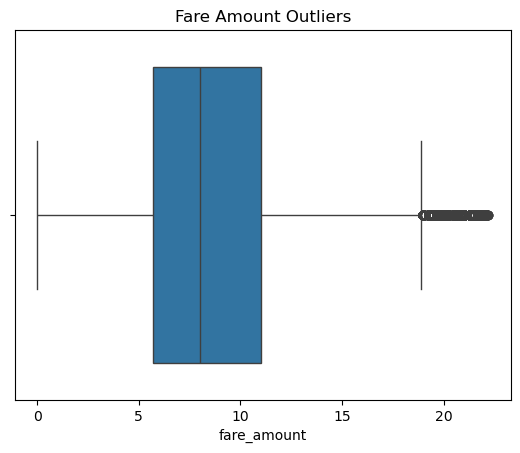

In [4]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

# Display boxplot
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()


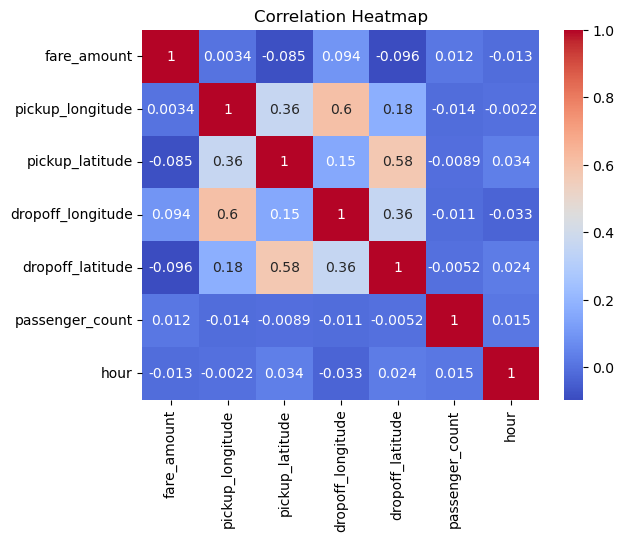

Correlation with Fare:
fare_amount          1.000000
dropoff_longitude    0.094383
passenger_count      0.012424
pickup_longitude     0.003404
hour                -0.012945
pickup_latitude     -0.085247
dropoff_latitude    -0.095517
Name: fare_amount, dtype: float64


In [5]:
correlation = df.corr()

# Display correlation heatmap
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# Display correlation with fare amount
print("Correlation with Fare:")
print(correlation['fare_amount'].sort_values(ascending=False))

In [6]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
lr = LinearRegression()

# Train the model
lr.fit(X_train, y_train)

# Predict fare
y_pred1 = lr.predict(X_test)

# Evaluate model
print("Linear Regression R2:", r2_score(y_test, y_pred1))

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred1)))

Linear Regression R2: 0.03357421252745396
Linear Regression RMSE: 4.071757708520595


In [8]:
rf = RandomForestRegressor(
    n_estimators=10,
    random_state=42
)

# Train the model
rf.fit(X_train, y_train)

# Predict fare
y_pred2 = rf.predict(X_test)

# Evaluate model
print("Random Forest R2:", r2_score(y_test, y_pred2))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred2)))

Random Forest R2: 0.7125516814001878
Random Forest RMSE: 2.220636933116751


In [9]:
print("Linear Regression R2:",
      r2_score(y_test, y_pred1))

print("Random Forest R2:",
      r2_score(y_test, y_pred2))

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred1)))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred2)))


Linear Regression R2: 0.03357421252745396
Random Forest R2: 0.7125516814001878
Linear Regression RMSE: 4.071757708520595
Random Forest RMSE: 2.220636933116751
